# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Define Priors

In [3]:
NSamps = 8000;

priorTheta = Array{Any}(undef, 13);
priotY0 = Array{Any}(undef, 3);

priorTheta[1] = Normal(40.92, 10); priorTheta[2] = Normal(51.23, 10); priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

global sampsTh = zeros(NSamps, 13);
global sampsY0 = zeros(NSamps, 3);

Random.seed!(687865443); 

for i in 1:13
    sampsTh[:,i] = rand(priorTheta[i], NSamps);
end
for i in 1:3
    sampsY0[:,i] = rand(priotY0[i], NSamps);
end

sampsTh[:,2] .= 51.23; # T1 of Pyruvate is fixed since it is irrelevant for the model for the problem and can be estimated with experiments without cells. 
sampsTh[:,13] .= 15; # This will be re-writen with the empirical value once extracted from data

In [4]:
bounds = [zeros(12), zeros(12)];
boundY0 = [[0, 0, 0], [1600, 4e4, 1600]];
for i in 1:12
    if i >= 3
        if priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4) >= 0
            bounds[1][i] = priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4);
        else
            bounds[1][i] = 0;
        end
        if priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4) <= 2
            bounds[2][i] = priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4);
        else
            bounds[2][i] = 2;
        end
    elseif i == 1
        bounds[1][i] = priorTheta[i].μ - (priorTheta[i].σ*4);
        bounds[2][i] = priorTheta[i].μ + (priorTheta[i].σ*4);
    elseif i == 2
        bounds[1][i] = 51.23;
        bounds[2][i] = 51.23;
    end
end

In [5]:
# priorInfer =  Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv", DataFrame))
priorInfer =  Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv", DataFrame))

8000×16 Matrix{Float64}:
 47.0209  51.23  0.0190752  0.0202484  …   373.041   21480.2  1430.41
 44.1484  51.23  0.0220342  0.0189998      563.724   14004.7   961.492
 48.8478  51.23  0.019956   0.0204499      243.162   22831.6  1237.69
 48.0088  51.23  0.019155   0.0214141      214.067   15227.8  1383.03
 50.3595  51.23  0.0213304  0.022624        88.1227  12370.1  1213.07
 37.9966  51.23  0.0145974  0.0167566  …  1200.8     27107.1  1241.38
 46.2821  51.23  0.0176245  0.0208012      156.076   12126.9  1170.18
 50.494   51.23  0.0194389  0.021762       271.178   19480.3  1017.7
 38.4183  51.23  0.0187112  0.0173605      953.664   17309.0  1370.89
 36.0838  51.23  0.0184488  0.0168619      955.243   13801.5  1343.43
  ⋮                                    ⋱                         ⋮
 44.8391  51.23  0.0187946  0.0186503      513.46    24671.9  1228.26
 45.7868  51.23  0.0185363  0.0189395      485.299   24551.6  1218.76
 40.036   51.23  0.0195125  0.0184574      696.903   16123.2  1313.8

# Optimal Experimental Design (OED)

In [6]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:13];
global sampsY0 = priorInfer[:,14:end];

In [7]:
CompRepUtil_Entro_OEDmc([15.0125])

103.59077646524186

## Optimisation

In [15]:
steps = 1;

In [16]:
model = ElasticGPE(steps,                            # 4*2 input dimensions
           mean = MeanConst(0.),
           kernel = SEArd(zeros(steps), 3.),
           logNoise = 0.,
           capacity = 3000);

In [17]:
modeloptimizer = MAPGPOptimizer(every = 50, noisebounds = [-4, 3],       # bounds of the logNoise
                               kernbounds = [[-1*ones(steps); 0], [4*ones(steps); 10]],  # bounds of the 3 parameters GaussianProcesses.get_param_names(model.kernel)
                               maxeval = 50);

┌ Warning: use values(kwargs) and keys(kwargs) instead of kwargs.data and kwargs.itr
│   caller = #MAPGPOptimizer#19 at gp.jl:37 [inlined]
└ @ Core C:\Users\dgomez\.julia\packages\BayesianOptimization\nq1HY\src\models\gp.jl:37


In [18]:
opt = BOpt(CompRepUtil_Entro_OEDmc,
          model,
          ExpectedImprovement(),                   # type of acquisition            UpperConfidenceBound
          modeloptimizer,
          [0.1],[40.], # lowerbounds, upperbounds
          repetitions = 1,                          # evaluate the function for each input 1 times
          maxiterations = 500,                      # evaluate at 50 input positions
          sense = Max,  
                                      # maximise the function
          acquisitionoptions = (method = :LD_LBFGS, # run optimization of acquisition function with NLopts :LD_LBFGS method
                restarts = 2,       # run the NLopt method from 5 random initial conditions each time.
                maxtime = 0.1,      # run the NLopt method for at most 0.1 second each time
                maxeval = 1000),    # run the NLopt methods for at most 1000 iterations (for other options see https://github.com/JuliaOpt/NLopt.jl
          verbosity = Progress);

In [19]:
result = boptimize!(opt)

┌ Info: 2025-04-02T13:02:45.664	iteration: 5	current optimum: 107.13734514771612
└ @ BayesianOptimization C:\Users\dgomez\.julia\packages\BayesianOptimization\nq1HY\src\BayesianOptimization.jl:140
┌ Info: 2025-04-02T13:02:53.935	iteration: 6	current optimum: 107.13734514771612
└ @ BayesianOptimization C:\Users\dgomez\.julia\packages\BayesianOptimization\nq1HY\src\BayesianOptimization.jl:140
┌ Info: 2025-04-02T13:02:58.912	iteration: 7	current optimum: 107.13734514771612
└ @ BayesianOptimization C:\Users\dgomez\.julia\packages\BayesianOptimization\nq1HY\src\BayesianOptimization.jl:140
┌ Info: 2025-04-02T13:03:04.002	iteration: 8	current optimum: 107.13734514771612
└ @ BayesianOptimization C:\Users\dgomez\.julia\packages\BayesianOptimization\nq1HY\src\BayesianOptimization.jl:140
┌ Info: 2025-04-02T13:03:06.590	iteration: 9	current optimum: 107.13734514771612
└ @ BayesianOptimization C:\Users\dgomez\.julia\packages\BayesianOptimization\nq1HY\src\BayesianOptimization.jl:140
┌ Info: 2025-04

(observed_optimum = 111.6796889166921, observed_optimizer = [8.2831022535207], model_optimum = 111.61477647489036, model_optimizer = [8.669351764765592])

In [20]:
inputOED = result.observed_optimizer

1-element Vector{Float64}:
 8.2831022535207

In [9]:
inputOED = 8.2831022535207;

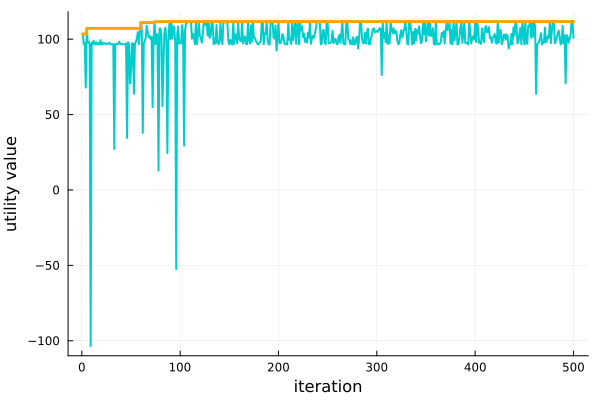

In [28]:
utilb = zeros(length(opt.model.y));
utilb[1] = opt.model.y[1];
for i in 2:length(opt.model.y)
    if opt.model.y[i]>=utilb[i-1]
        utilb[i] = opt.model.y[i];
    else
        utilb[i] = utilb[i-1];
    end
end

plot(opt.model.y, label = "", xlabel = "iteration", ylabel = "utility value", color="cyan3", linewidth = 2)
plot!(1:length(utilb), utilb, label = "", linetype=:step, color="orange", linewidth = 3)

### Save resutls

In [29]:
JLD2.save(string("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\OptimisationResults_Seq\\CRExp_SeqOED_OED2_OEDmc.jld"), "result", result, "inputOED",inputOED)

In [23]:
optres = Dict("acquisitionoptions"=>opt.acquisitionoptions,
                "duration"=>opt.duration,
#                 "func"=>opt.func,
#                 "initializer"=>opt.initializer,
#                 "iterations"=>opt.iterations,
#                 "iterations"=>opt.iterations,
#                 "lowerbounds"=>opt.lowerbounds,
#                 "model"=>opt.model,
                "model_optimizer"=>opt.model_optimizer,
                "model_optimum"=>opt.model_optimum,
                "modeloptimizer"=>opt.modeloptimizer,
                "observed_optimizer"=>opt.observed_optimizer,
                "observed_optimum"=>opt.observed_optimum,
#                 "opt"=>opt.opt,
                "repetitions"=>opt.repetitions,
                "sense"=>opt.sense,
#                 "timeroutput"=>opt.timeroutput,
                "upperbounds"=>opt.upperbounds,
#                 "verbosity"=>opt.verbosity,
                "modelX"=>Array(opt.model.x),
                "modelY"=>Array(opt.model.y));
JLD2.save(string("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\OptimisationResults_Seq\\CRExp_SeqOED_OED2_OEDmc2.jld"), optres)

In [10]:
PyrCons = [round(JLD2.load(string("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\OptimisationResults_Seq\\CRExp_SeqOED_OED2_OEDmc.jld"))["inputOED"][1], digits=1)]

1-element Vector{Float64}:
 8.3

In [8]:
CompRepUtil_Entro_OEDmc([8.3])

111.67968891669209

## Simulate Experiment Prio Prediction

In [11]:
simsPrior = Array{Any}(undef, 8000);

tsC2 = vcat(0, collect(15:5:395));
for i in 1:8000
    ts = 0:tsC2[end];
    ivss = [round(PyrCons[1], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(PyrCons[1], digits = 1)*1000, 0, round(PyrCons[1], digits = 1)*1000*(priorInfer[1,13]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);
    simsPrior[i] = SimulsAll;
end

In [12]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];
for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end

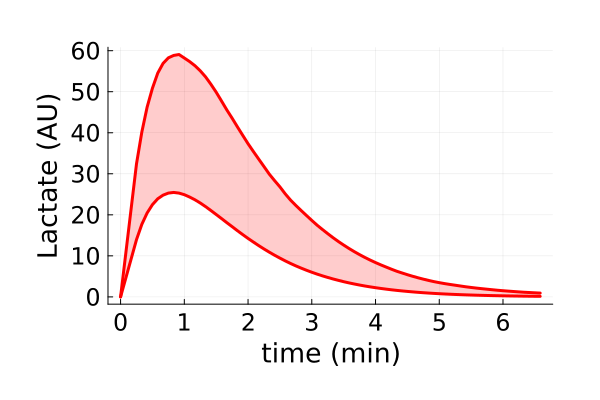

In [13]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "red", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "red", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="red", fillalpha=0.2)

# .................................................... PERFORM EXPERIMENT ....................................................

103.75 uL of pyruvate + 146.25 uL of media from the 20 mM solution 
<br>
51.875 uL of pyruvate + 198.125 uL of media from the 40 mM solution 
<br>
25.9375 uL of pyruvate + 224.0625 uL of media from the 80 mM solution

# Extract Experimental Data 3.2 mM, 0.6 mM and 8.3 mM

In [19]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_8-3mMPyr_Dat.csv"];
conce = [3.2, 0.6, 8.3];

In [20]:
Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1])

Dict{String, Any} with 15 entries:
  "Means"  => [9177.49 1226.15 22629.9; 6162.55 723.012 14522.9; … ; -6.00262 0…
  "stsl"   => [77 77 76]
  "obSta"  => [1 2]
  "sts"    => [0 0 0; 20 20 25; … ; 390 390 395; 395 395 0]
  "obser"  => 2
  "Y0us"   => [3200.0 600.0 8300.0; 0.0 0.0 0.0; … ; 0.0 0.0 0.0; 9177.49 1226.…
  "ts"     => [1.0e-20 1.0e-20 1.0e-20; 1.0 1.0 1.0; … ; 394.0 394.0 394.0; 395…
  "itp"    => [0.0, 0.0, 0.0]
  "ScFms"  => [23.8997 17.0298 22.7208]
  "ncells" => [4 4 4]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [821.947 81.2187 1802.69; 491.932 72.3012 1401.01; … ; 7.38584 4.…
  "m"      => 3
  "nts"    => [395 395 395]

# Simulate Experiment Prior Prediction

In [28]:
simsPrior = Array{Any}(undef, 8000);
sampsTh[:,13] .= dat["ScFms"][end];

tsC2 = dat["sts"];
for i in 1:8000
    tsC2 = dat["sts"][1:end-1,end];
    ts = 0:tsC2[end];
    ivss = [round(conce[end], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);

    simsPrior[i] = SimulsAll;
end

In [29]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


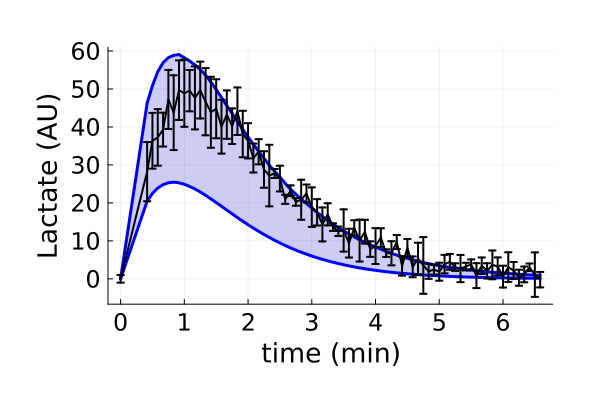

In [31]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][1:end-1,end]./60, dat["Means"][1:end-1,end,2], yerror = dat["Erros"][1:end-1,end,2], linewidth = 2, colour = "black", label = "")

# MLE to obtain a good first guess for inference

In [34]:
function ObjectFunctMECp_Multi_MLE(p)

    # Define parameter vectors for each amount of cells (last parameter is a time delay, not used in here)
    
    obj = 0;
    
    for i in 1:length(dat["stsl"])
        pD2 = vcat(p[1:end-3], dat["ScFms"][i], 0);

        # Define time vector
        if i == 3
            t2cor = dat["sts"][1:end-1,i];
        else
            t2cor = dat["sts"][:,i];
        end
        # Define equaly-spaced time vector
        ts1 = collect(0:t2cor[end]);

        # Define initial value for simulation (use of experimental mean)
        ivss1 = [dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), 0, dat["Means"][1,i,2]/(dat["ScFms"][i]*0.12), p[end-2], p[end-1], p[end], 0, 0, 0, 0, 0, dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), dat["Means"][1,i,2], dat["Means"][1,i,1]];

        # Convert sampling vector to integer to extract correct elements from simulation
        samps1 = convert.(Int, t2cor);

        # Simulate
        SimOnTime1, SimOffTime1, SimAll1  = PyruvateHP_NMR_SolveAllCp(ts1, pD2, ivss1, samps1);
    
        # mm11 = sum((-1/2) .* (log(2*pi) .+ log.((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2) .+ (((SimOnTime1[:,14]/maximum(dat["Means"][:,i,1])) .- 
        #                 (dat["Means"][:,i,1]/maximum(dat["Means"][:,i,1]))).^2)./((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2)));

        if i == 3
            mm11 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][1:end-1,i,1].^2) .+ ((SimOnTime1[:,14] .- dat["Means"][1:end-1,i,1]).^2)./(dat["Erros"][1:end-1,i,1].^2)));
            mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][1:end-1,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][1:end-1,i,2]).^2)./(dat["Erros"][1:end-1,i,2].^2)));
        else
            mm11 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,1].^2) .+ ((SimOnTime1[:,14] .- dat["Means"][:,i,1]).^2)./(dat["Erros"][:,i,1].^2)));
            mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][:,i,2]).^2)./(dat["Erros"][:,i,2].^2)));
        end
        
        
        # println(mm11)
        # obj = (mm21+mm22)*(mm11+mm12);
        if p[end-2] >= p[end-1]
            mm22 = mm22*10;
        end
        # obj = -(mm22)+obj;
        obj = -(mm22)+sqrt(abs(mm11))+obj;
    end
    
    return(obj)

end

ObjectFunctMECp_Multi_MLE (generic function with 1 method)

In [35]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE(p)

2796.7268327951947

In [36]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:12], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*8, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.50 secs, 38 evals, 19 steps, improv/step: 0.421 (last = 0.4211), fitness=1541.553731915
1.05 secs, 68 evals, 36 steps, improv/step: 0.417 (last = 0.4118), fitness=1541.553731915
1.55 secs, 121 evals, 66 steps, improv/step: 0.470 (last = 0.5333), fitness=1541.553731915
2.05 secs, 161 evals, 98 steps, improv/step: 0.429 (last = 0.3438), fitness=1541.553731915
2.57 secs, 199 evals, 125 steps, improv/step: 0.448 (last = 0.5185), fitness=1541.553731915
3.07 secs, 253 evals, 167 steps, improv/step: 0.425 (last = 0.3571), fitness=1541.553731915
3.57 secs, 285 evals, 195 steps, improv/step: 0.426 (last = 0.4286), fitness=1440.582229162
4.08 secs, 327 evals, 233 steps, improv/step: 0.403 (last = 0.2895), fitness=1440.582229162
4.59 secs, 383 evals, 283 steps, improv/step: 0.385 (last = 0.3000

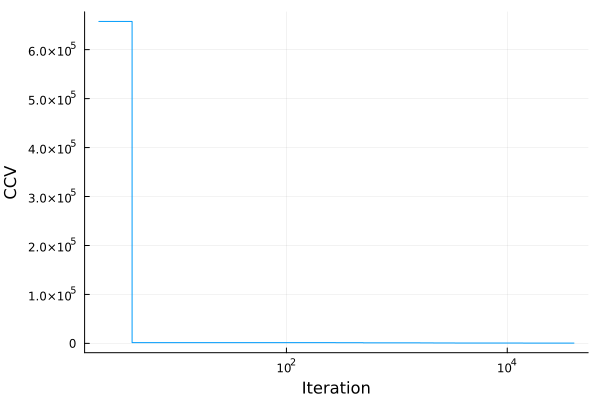

In [37]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

In [38]:
# Extract Parameter Vector
parfitT = zeros(15, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind]

15-element Vector{Float64}:
    38.16312822539201
    51.23
     0.01949908595298083
     0.013157746939040284
     0.04366033443705924
     1.741676877309218
     0.5190323013727703
     1.9632759460656493
     0.7215670981324438
     0.04244645244390279
     0.4388903089141911
     7.318778698794126e-5
   333.8207861372075
 39514.21965079889
  1597.657488345541

In [39]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMTRRCmp_Exper_OED2.jld2", "FitsT",FitsT)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_OED2.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

┌ Warning: Attempting to store var"#95#96".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [40]:
ppT = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_OED2.jld2")["resMMat"][:,1]


15-element Vector{Float64}:
    38.16312822539201
    51.23
     0.01949908595298083
     0.013157746939040284
     0.04366033443705924
     1.741676877309218
     0.5190323013727703
     1.9632759460656493
     0.7215670981324438
     0.04244645244390279
     0.4388903089141911
     7.318778698794126e-5
   333.8207861372075
 39514.21965079889
  1597.657488345541

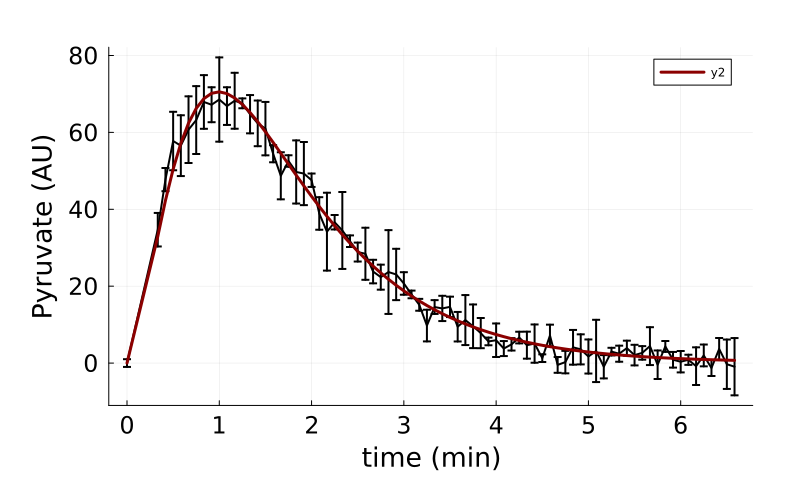

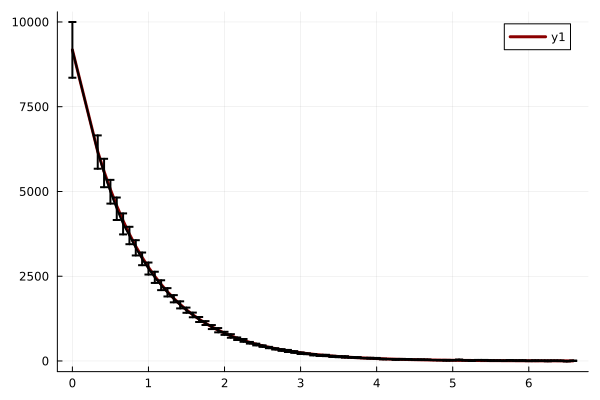

In [41]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,1];
ts = 0:tsC2[end];
ivss = [round(conce[1], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][1], 0), ivss, samps);

pps = plot(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)


ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

display(ps)

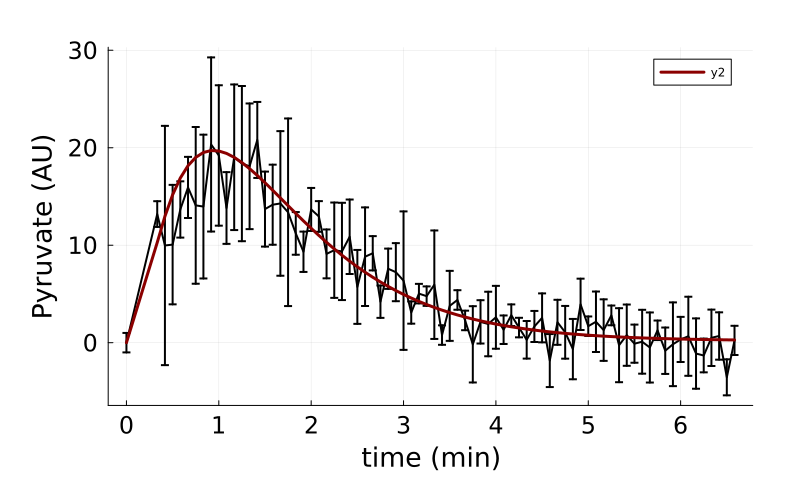

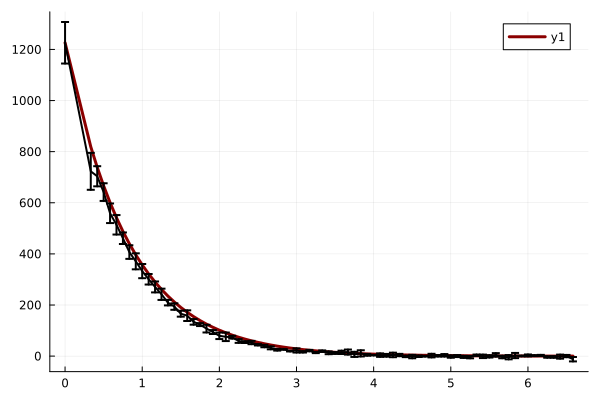

In [42]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,2];
ts = 0:tsC2[end];
ivss = [round(conce[2], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[2], digits = 1)*1000, 0, round(conce[2], digits = 1)*1000*(dat["ScFms"][2]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][2], 0), ivss, samps);

pps = plot(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")

display(ps)

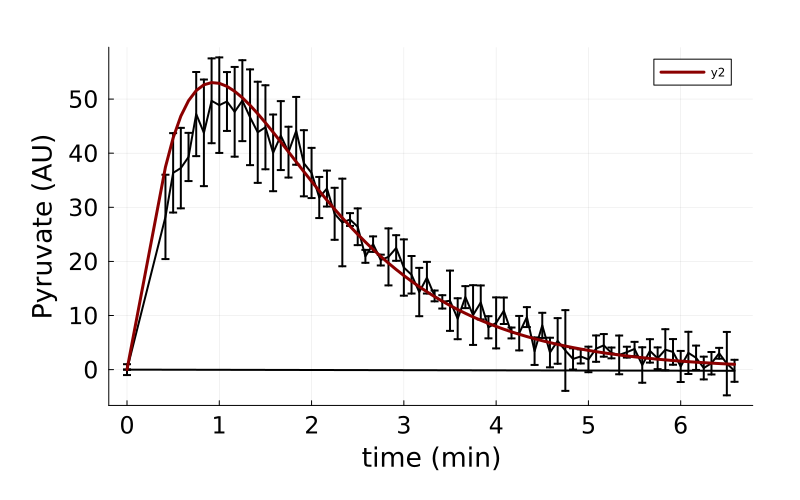

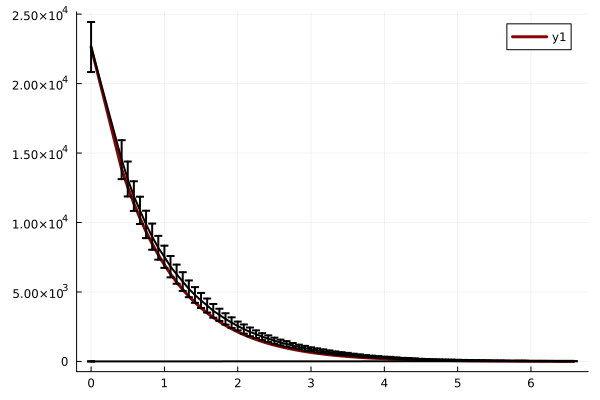

In [47]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][1:end-1,end];
ts = 0:tsC2[end];
ivss = [round(conce[end], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][end], 0), ivss, samps);

pps = plot(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,end]./60, dat["Means"][:,end,1], yerror = dat["Erros"][:,end,1], linewidth = 2, colour = "black", label = "")

display(ps)

## Compute structure for Stan's initial guess

In [44]:
preTrans = zeros(14);

preTrans[1] = (ppT[1]-40.92)/10; 
preTrans[2] = (ppT[3]-0.0055)/0.0055; 
preTrans[3] = (ppT[4]-0.0275)/0.0275;          
preTrans[4] = (ppT[5]-0.045)/0.045;
preTrans[5] = (ppT[6]-0.45)/0.45;
preTrans[6] = (ppT[7]-0.95)/0.95;
preTrans[7] = (ppT[8]-0.95)/0.95;
preTrans[8] = (ppT[9]-0.95)/0.95;
preTrans[9] = (ppT[10]-0.0085)/0.0085;
preTrans[10] = (ppT[11]-0.95)/0.95;
preTrans[11] = (ppT[12]-0.0029)/0.0029;


preTrans[12] = (ppT[13]-650)/260;
preTrans[13] = (ppT[14]-16000)/6400;
preTrans[14] = (ppT[15]-550)/275;

In [45]:

samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict(samps, names, 4)

4-element Vector{Dict{String, Any}}:
 Dict("kbnE" => 3.9937002875179752, "LDH" => 3.8096635939837853, "kin" => 2.5452883550874237, "ki" => -0.5380102011429567, "kunE" => -0.24045568617637492, "kpl" => -0.5215364749439897, "NADH" => -1.2160738994722788, "kup" => 1.066606259016473, "T1_X" => -0.2756871774607994, "kbp" => -0.45365020908129433…)
 Dict("kbnE" => 3.9937002875179752, "LDH" => 3.8096635939837853, "kin" => 2.5452883550874237, "ki" => -0.5380102011429567, "kunE" => -0.24045568617637492, "kpl" => -0.5215364749439897, "NADH" => -1.2160738994722788, "kup" => 1.066606259016473, "T1_X" => -0.2756871774607994, "kbp" => -0.45365020908129433…)
 Dict("kbnE" => 3.9937002875179752, "LDH" => 3.8096635939837853, "kin" => 2.5452883550874237, "ki" => -0.5380102011429567, "kunE" => -0.24045568617637492, "kpl" => -0.5215364749439897, "NADH" => -1.2160738994722788, "kup" => 1.066606259016473, "T1_X" => -0.2756871774607994, "kbp" => -0.45365020908129433…)
 Dict("kbnE" => 3.9937002875179752, "LDH" 

In [48]:
ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 3.9937
  "LDH"  => 3.80966
  "kin"  => 2.54529
  "ki"   => -0.53801
  "kunE" => -0.240456
  "kpl"  => -0.521536
  "NADH" => -1.21607
  "kup"  => 1.06661
  "T1_X" => -0.275687
  "kbp"  => -0.45365
  "kr"   => -0.974763
  "NAD"  => 3.6741
  "kun"  => 2.87039
  "kbn"  => -0.0297703

# Inference

In [49]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_OED2_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 600, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;


File d:\David\BayesianInferencesInVivoScripts\ExperimentalBayesianOED\tmp\PyrCompRepr_OED2_Try1.stan will be updated.



In [ ]:
# modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit2.stan";

In [50]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_OED2_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(600,600,600,600,600,600,600,600,600,600); thin=(1,1,1,1,1,1,1,1,1,1); 14000 iterations saved.

Warmup took (74036, 78559, 72360, 73787, 73982, 75383, 72749, 77682, 77268, 75057) seconds, 209 hours total
Sampling took (125245, 118242, 120038, 119466, 113915, 116169, 121477, 111116, 100655, 128597) seconds, 326 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -5.8e+02  6.0e-02  3.0e+00  -5.9e+02  -5.8e+02  -5.8e+02  2.5e+03  2.1e-03  1.0e+00
accept_stat__    9.5e-01  9.2e-04  8.4e-02   7.8e-01   9.8e-01      1.00  8.3e+03  7.1e-03  1.0e+00
stepsize__       7.2e-03  2.1e-04  2.2e-03   4.0e-03   7.2e-03     0.011  1.1e+02  9.2e-05  1.0e+00
treedepth__      9.0e+00  5.1e-02  6.7e-01   8.0e+00   9.0e+00        10  1.7e+02  1.4e-04  1.0e+00
n_leapfrog__     6.4e+02  1.4e+01  2.7e+02  

(0, [-597.101 0.995175 … 39226.1 1577.74; -597.101 0.0 … 39226.1 1577.74; … ; -586.941 0.955325 … 19454.2 995.22; -588.436 0.996813 … 16963.9 1552.34;;; -602.098 0.00148119 … 39514.2 1597.66; -602.098 0.0 … 39514.2 1597.66; … ; -586.177 0.975144 … 33193.8 1195.34; -583.151 0.900924 … 8695.09 1350.87;;; -602.098 2.48333e-164 … 39514.2 1597.66; -602.098 0.0 … 39514.2 1597.66; … ; -579.7 0.998623 … 19166.3 1284.11; -586.675 0.999686 … 34513.3 1414.71;;; -596.023 0.990957 … 39593.6 1597.06; -596.023 0.0 … 39593.6 1597.06; … ; -580.217 0.999949 … 22482.2 1483.26; -583.729 0.976054 … 16490.7 1568.85;;; -587.816 0.940454 … 22664.7 1198.11; -587.816 0.0 … 22664.7 1198.11; … ; -580.944 0.789453 … 21227.8 1151.95; -582.612 0.971791 … 10708.2 1232.46;;; -587.782 0.864163 … 11579.1 1228.52; -587.782 0.0 … 11579.1 1228.52; … ; -585.293 0.98629 … 21301.4 1392.37; -584.093 0.999968 … 12033.6 1356.74;;; -592.476 0.892969 … 30980.6 1512.85; -592.476 0.0 … 30980.6 1512.85; … ; -583.865 0.999251 … 16948.

In [54]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PyrCompetitiveRepressionInferExp_OED2_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [55]:
poster = vcat(chns[401:end, end-15:end, 1], chns[401:end, end-15:end, 2], chns[401:end, end-15:end, 3], chns[401:end, end-15:end, 4], chns[401:end, end-15:end, 5], 
              chns[401:end, end-15:end, 6], chns[401:end, end-15:end, 7], chns[401:end, end-15:end, 8], chns[401:end, end-15:end, 9], chns[401:end, end-15:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED2_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED2_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED2_Try1.csv"

In [56]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED2_Try1.csv", DataFrame))

10000×16 Matrix{Float64}:
 43.6593  51.23  0.0213655  0.0141987  …  22.7208  527.055  14058.5  1371.7
 43.6659  51.23  0.0221122  0.0140989     22.7208  587.341  13305.4  1347.73
 38.8097  51.23  0.0183385  0.0133705     22.7208  618.563  18400.0  1270.12
 37.4523  51.23  0.0201967  0.0123474     22.7208  748.67   20643.8  1222.36
 37.3868  51.23  0.0203976  0.0123434     22.7208  736.693  20599.0  1231.61
 38.2114  51.23  0.0170493  0.0132564  …  22.7208  566.028  22511.2  1342.72
 36.6042  51.23  0.0162009  0.0127843     22.7208  495.349  21423.6  1334.85
 48.6064  51.23  0.0213283  0.0153674     22.7208  698.394  25140.6  1342.41
 43.9016  51.23  0.0205906  0.014865      22.7208  718.427  15495.7  1321.89
 41.6028  51.23  0.0195495  0.0137596     22.7208  680.4    26953.6  1170.76
  ⋮                                    ⋱                                ⋮
 41.1474  51.23  0.0198403  0.0134487     22.7208  702.287  23023.2  1313.35
 40.7416  51.23  0.0189491  0.0135847     22.7208  739

# Plot Posterior VS Prior

In [57]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [59]:
priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

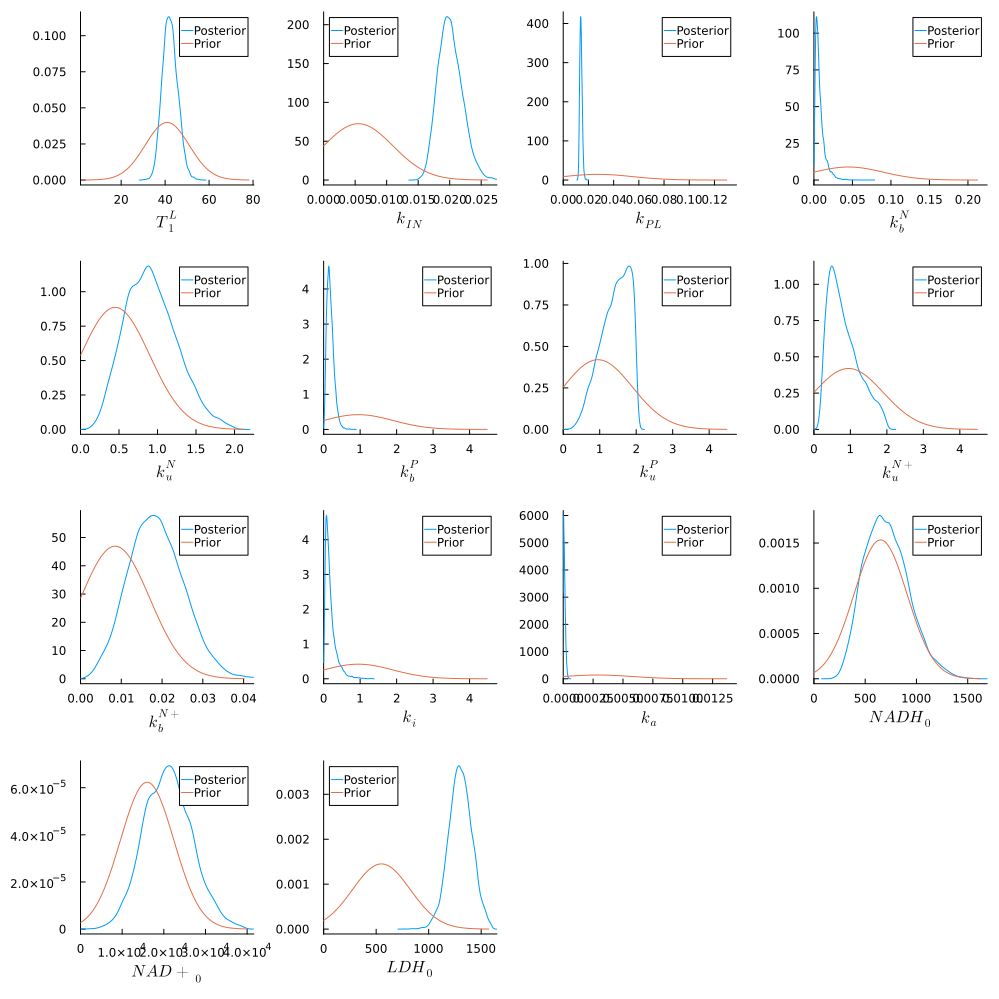

In [60]:
pp0 = plot(kde(poster[:,1]), label = "Posterior", xlabel = namess[1])
plot!(Normal(40.92, 10), label = "Prior")

pp1 = plot(kde(poster[:,3]), label = "Posterior", xlabel = namess[2])
plot!(Normal(0.0055, 0.0055), label = "Prior", xlim = (0, 0.0055+4*0.0055))

pp2 = plot(kde(poster[:,4]), label = "Posterior", xlabel = namess[3])
plot!(Normal(0.0275, 0.0275), label = "Prior", xlim = (0, 0.0275+4*0.0275))

pp3 = plot(kde(poster[:,5]), label = "Posterior", xlabel = namess[4])
plot!(Normal(0.045, 0.045), label = "Prior", xlim = (0, 0.045+4*0.045))

pp4 = plot(kde(poster[:,6]), label = "Posterior", xlabel = namess[5])
plot!(Normal(0.45, 0.45), label = "Prior", xlim = (0, 0.45+4*0.45))

pp5 = plot(kde(poster[:,7]), label = "Posterior", xlabel = namess[6])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp6 = plot(kde(poster[:,8]), label = "Posterior", xlabel = namess[7])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp7 = plot(kde(poster[:,9]), label = "Posterior", xlabel = namess[8])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp8 = plot(kde(poster[:,10]), label = "Posterior", xlabel = namess[9])
plot!(Normal(0.0085, 0.0085), label = "Prior", xlim = (0, 0.0085+4*0.0085))

pp9 = plot(kde(poster[:,11]), label = "Posterior", xlabel = namess[10])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp10 = plot(kde(poster[:,12]), label = "Posterior", xlabel = namess[11])
plot!(Normal(0.0029, 0.0029), label = "Prior", xlim = (0, 0.0029+4*0.0029))


pp11 = plot(kde(poster[:,14]), label = "Posterior", xlabel = namess[12])
plot!(Normal(650, 260), label = "Prior", xlim = (0, 650+4*260))

pp12 = plot(kde(poster[:,15]), label = "Posterior", xlabel = namess[13])
plot!(Normal(16000, 6400), label = "Prior", xlim = (0, 16000+4*6400))

pp13 = plot(kde(poster[:,16]), label = "Posterior", xlabel = namess[14])
plot!(Normal(550, 275), label = "Prior", xlim = (0, 550+4*275))

plot(pp0,pp1,pp2,pp3,pp4,pp5,pp6,pp7,pp8,pp9,pp10,pp11,pp12,pp13, size=(1000,1000), grid = false)

In [62]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,14:end]))))

47.90565201595905

In [63]:
using CairoMakie
using PairPlots
using DataFrames

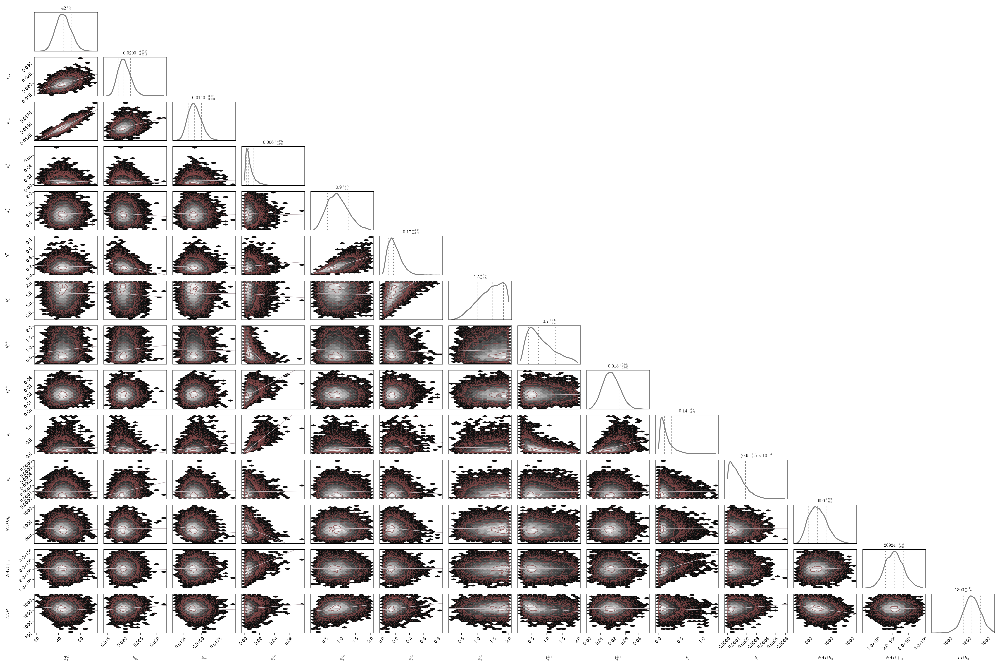

In [64]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,14:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_OED2bExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

In [73]:
simsPoster = Array{Any}(undef, 8000, 3);

for j in 1:3
for i in 1:8000
    if j == 3
        tsC2 = dat["sts"][1:end-1,j];
    else
        tsC2 = dat["sts"][:,j];
    end
    ts = 0:tsC2[end];
    ivss = [dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, 0, poster[i,14], poster[i,15], poster[i,16], 0, 0, 0, 0, 0, dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, dat["Means"][1,j,1]];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster[i,1:12], dat["ScFms"][j], 0), ivss, samps);

    simsPoster[i,j] = SimulsAll;
end
end

In [66]:
dat["ScFms"]

1×3 Matrix{Float64}:
 23.8997  17.0298  22.7208

### Experiment 1

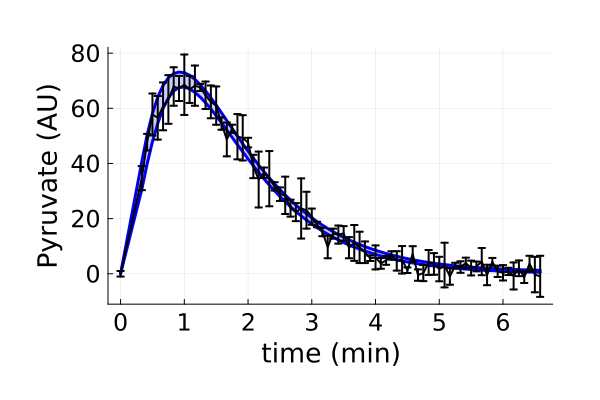

attempt to save state beyond implementation limit


In [89]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,1][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end
tsC2 = dat["sts"][:,1];
pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")


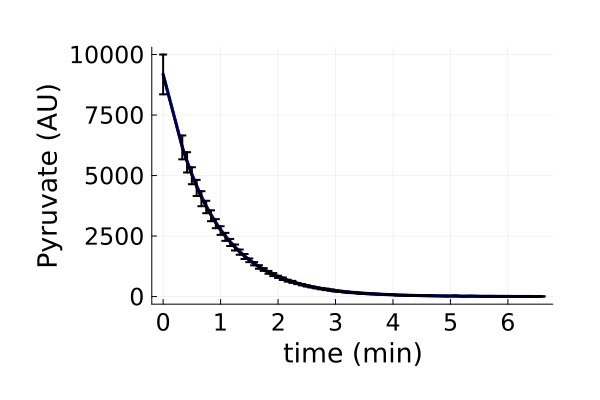

In [90]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,1][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end
tsC2 = dat["sts"][:,1];
pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

## Experiment 2

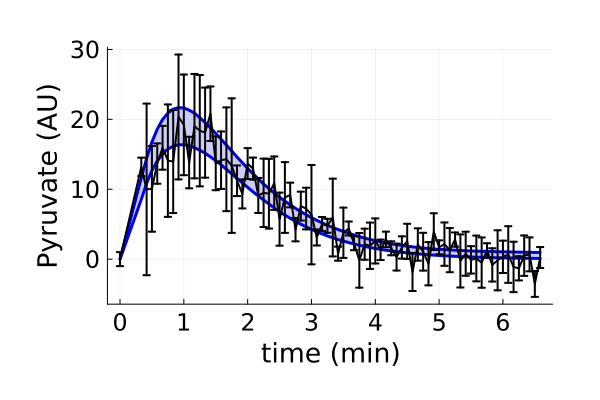

In [91]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,2][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end
tsC2 = dat["sts"][:,2];
pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "")

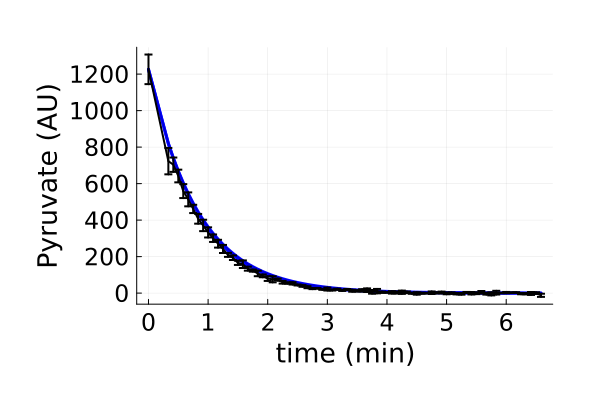

In [92]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,2][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

tsC2 = dat["sts"][:,2];

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")

## Experiment 3

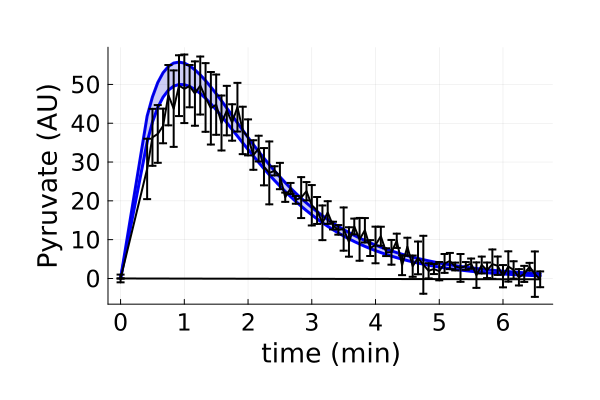

In [94]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,3])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,3][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end
tsC2 = dat["sts"][1:end-1,3];
pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,3]./60, dat["Means"][:,3,2], yerror = dat["Erros"][:,3,2], linewidth = 2, colour = "black", label = "")

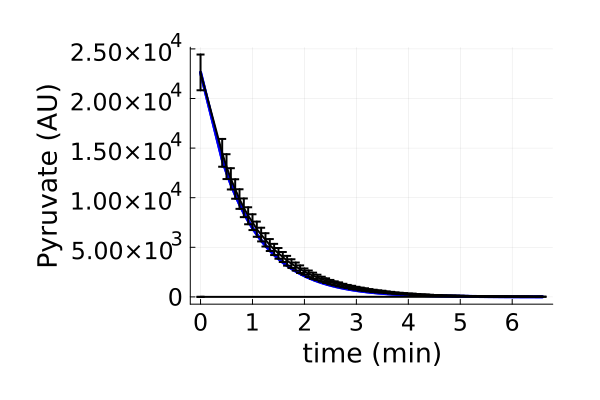

In [104]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,3])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,3][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end
tsC2 = dat["sts"][1:end-1,3];
pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,3]./60, dat["Means"][:,3,1], yerror = dat["Erros"][:,3,1], linewidth = 2, colour = "black", label = "")